# Electrostatic Simulations Using Python

## Basic theory
This explanation is largely taken from [Geeksforgeeks](https://www.geeksforgeeks.org/simulating-electrostatic-fields-in-2-dimensions-using-python3/). We will use direct integration to calculate the electric field vector at every point on a grid. Recall, the formula for direct integration is:

$$ \vec{E} = \dfrac{Q}{4\pi\varepsilon r^3} \vec{r}$$

For free space propagation, we have $\dfrac{1}{4\pi\varepsilon} = k \approx 9\times 10^{9}$, which leads to a simplified equation:

$$\vec{E} = \dfrac{kQ}{r^3} \vec{r}$$

For our 2-D application $\vec{r}\hspace{1pt}$ can be decomposed into $x$ and $y$ components as $\vec{r} = \hat{x} r_x + \hat{y} r_y$, where $r_x$ and $r_y$ are the distances from the charge $Q$ to our observation point. Furthermore, the magnitude of $\vec{r}\hspace{1pt}$ is given by  $\sqrt{r_x^2 + r_y^2}$. This helps us decompose the electric field into the following form:


$$\vec{E} = \hat{x} E_x + \hat{y} E_y = \dfrac{Qk}{r^3} \left[ \hat{x} r_x + \hat{y} r_y \right]$$
 
Using this form, we can calculate the distance from each charge, $q_n$, to each point $(x_p, y_p)$ on our grid using:

$$ r_x = x_p - x_{q_n}$$
$$ r_y = y_p - y_{q_n}$$
$$| r | = \sqrt{r_x^2 + r_y^2} $$

and subsequently calculate the $E_x$ and $E_y$ components from each charge by:

$$E_x = \dfrac{q_n k}{r^3} r_x $$
$$E_y = \dfrac{q_n k}{r^3} r_y $$

The following code defines a function to calculate $E_x$ and $E_y$:

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def calcEfield(xrng: list, yrng: list, npts: int, Q: list):
    x1, x2 = xrng # define the x range
    y1, y2 = yrng # define the y range
    xpts = npts # x resolution
    ypts = npts # y resolution
    #dx = (x2 - x1) / xpts # not needed at the moment
    #dy = (y2 - y1) / ypts # not needed at the moment
    x, y = np.linspace(x1, x2, xpts), np.linspace(y1, y2, ypts) # create 1D vectors for x & y
    x, y = np.meshgrid(x, y) # create a meshgrid for x and y. We will use this as the coordinates of our system
    Ex = np.zeros((xpts, ypts)) # init Ex
    Ey = np.zeros((xpts, ypts)) # init Ey

    k = 9 * 10 ** 9 # 1/(4*pi*eps)...ish
    for i in range(xpts): # for each point on our grid, we'll calculate Ex and Ey due to the source charges
        for j in range(ypts):
            xp, yp = x[i][j], y[i][j] # this is the current point, looping over all points
            for q in Q: # need to calculate Ex and Ey for each charge, Q is a list of tuples [(x1,y1,q1),(x2,y2,q2),...]
                rX = xp - q[0] # x distance from the current point to the current charge 
                rY = yp - q[1] # y distance from the current point to the current charge

                rmag = (rX ** 2 + rY ** 2) ** 0.5 # magnitude of r vector 

                E = (k * q[2]) / (rmag ** 3) # calculate the magnitude of E at this point from this charge
                Ex[i][j] += E * (rX) # add the contribution of this charge to the total electric field at the coordinate (xp,yp), which is (i,j) on the meshgrid
                Ey[i][j] += E * (rY) # add the contribution of this charge to the total electric field at the coordinate (xp,yp), which is (i,j) on the meshgrid
    return x, y, Ex, Ey

Now, we can test this by placing a single point charge at the origin. $Q$ is a list of tuples, where the values of the tuple are (xqn, yqn, charge value). The resultant plot comes from reconstructing the electric field vector from its constituent parts:

$$ \vec{E} = \hat{x} E_x + \hat{y} E_y$$

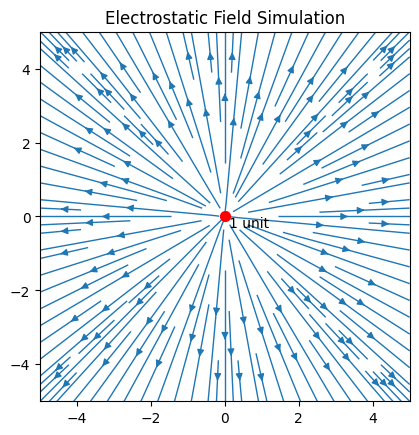

In [10]:
# Single charge at the origin
Q = [(0,0,1)] # a charge of unit 1 at (0,0)
numpts = 100 # this is x and y resolution
xrange = [-5, 5] # our grid will go from -5 to 5
yrange = [-5, 5]
x, y, Ex, Ey = calcEfield(xrange, yrange, numpts, Q) # use the function from above to calculate the x and y components. 

# now, we plot the Ex and Ey components using streamplot, which is similar to quiver in Matlab
fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.scatter([q[0] for q in Q], [q[1] for q in Q], c='red', s=[abs(q[2]) * 50 for q in Q], zorder=1) # plot each charge according to its size
for q in Q: ax.text(q[0] + 0.1, q[1] - 0.3, '{} unit'.format(q[2]), color='black', zorder=2) # labels for each charge
ax.streamplot(x, y, Ex, Ey, linewidth=1, density=1.5, zorder=0) # actually plot the electric field components
plt.title('Electrostatic Field Simulation') 
plt.show()

Question: Looking at the resulting plot - does it make sense? Are all the Electric field lines moving away from the charge?

Answer: 

Now, what if we wanted to test **Gauss' Law** against this simple point charge? We can't use the integral form, because it's a 3D equation and it doesn't reduce well to 2D. However, the point form might work. In rectangular coordinates, the divergence is:

$$\nabla\cdot \vec{E} = \dfrac{\rho}{\varepsilon}$$
$$\dfrac{\partial E_x}{\partial x} + \dfrac{\partial E_y}{\partial y} + \dfrac{\partial E_z}{\partial z} = \dfrac{\rho}{\varepsilon}$$

Since we are in 2D, the $z$-component of the electric field (and associated partial derivatives) are zero. We can calculate this divergence on our grid using the method of **finite differences**, meaning we approximate derivatives by calculating the change in the electric field components as we move one coordinate point to the left and right, then divide by the step. In order to do this properly, we must move in both directions (left and right/up and down). The following function calculates this divergence.


In [14]:
## compute divergence using the point form of Gauss' Law
def calcDiv(Ex: list, Ey: list, xc: int,yc: int,xstep: float, ystep: float): # xc and yc are the indices of the points we want to use
    xd1 =  (Ex[xc-1][yc]-Ex[xc][yc])/ (xstep) # moving left and finding finite difference in Ex
    xd2 =  (Ex[xc+1][yc]-Ex[xc][yc])/ (xstep) # moving right and finding finite difference in Ex
    yd1 =  (Ey[xc][yc-1]-Ey[xc][yc])/ (ystep) # moving up in y and finding finite difference in Ey
    yd2 =  (Ey[xc][yc+1]-Ey[xc][yc])/ (ystep) # moving down in y and finding finite difference in Ey
    div = (xd1 + xd2 + yd1 + yd2)*(8.854*10**(-12)) # multiply by permittivity to get charge density
    return div

calcDiv(Ex, Ey, 48, 48, 0.1,0.1) # calculates the divergence at x[25], y[25]

np.float64(-19.639486995433693)

**Task**: Use the calcDiv function to create a heatmap of the divergence values across the $x,y$ grid.

In [ ]:
# Code to create heatmap


Welcome to the world of *computational electromagnetics*! Well, it's actually computational electrostatics, but this is a good start! Your task is to use the Coulomb's Law function we developed to create more complex charge distributions:

- Dipole (two separated charges of opposite charge)
- Line charge 
- Two line charges of opposite charge (similar to your homework)
- Something interesting!


Use the cells below to develop your code and submit the final result. Don't worry about calculating Gauss' Law, unless you want to go above and beyond (which might benefit you in the future?).

***
# Dipole
***

In [ ]:
# Dipole - add your parameters here, and add code to plot the E-field.
Q = []
numpts = 0
xrange = []
yrange = []


## Dipole anlaysis

1) Does the resulting plot look anything like what you expected?

***
# Line charge
***

In [ ]:
# Line charge - add your parameters here, and add code to plot the E-field.

Q = []
numpts = 100
xrange = [-5,5]
yrange = [-5,5]

## Line charge analysis (Answer the following questions):

1) Does the resulting plot look anything like what you expected? 

2) How do you see the infinite line assumption from class breaking down?  


***
# Two Line Charges
***

In [ ]:
# Two line charges
Q = []
numpts = 0
xrange = []
yrange = []

## Two line charges analysis (answer the following questions):

1) How does creating two line charges change the electric field from just one line charge?

2) Can you identify a point in between the line charges where the electric field is 0? 

***
# A Novel Charge Distribution
***

In [ ]:
# A novel shape -- build something interesting and describe what you did
Q = []
numpts = 0
xrange = []
yrange = []


## Novel Charge Distribution Analysis

\[Describe your experiment\]